# Bien público: financiar un subsidio no es gratis

## Resumen
En el modelo sintético de dos agentes, un matching que ignora la distorsión fiscal puede reducir bienestar frente a no intervenir. Se deriva una corrección analítica y se contrasta con optimización escalar en30casos. S2 local; no recomendación fiscal real.

## Tres ideas y selección
Se compararon HAC para IV, inferencia robusta al sesgo RD y provisión de bien público con coste fiscal. Se eligió el tercero por ser nuevo y pequeño, con identidad presupuestaria y oráculo independientes. No se afirma algoritmo mundial nuevo.

## Modelo económico

Dos agentes con $0<\theta_L<\theta_H$, $\theta_H>1$. Utilidad $\theta_i\log(1+G)-(1-s)g_i-T_i$, $G=g_L+g_H$. Transferencias fijas $T_i$ se anuncian antes de elegir; suman $sG$ **en el equilibrio previsto**, no ante toda desviación. Ningún agente internaliza cambios marginales del impuesto. Preferencias conocidas y sin restricciones presupuestarias.

Nash: solo el tipo alto contribuye, $G(s)=\theta_H/(1-s)-1$. Sin política $G_0=\theta_H-1$. El objetivo sin coste fiscal tiene $G_{FB}=\theta_L+\theta_H-1$. No modelamos altruismo cálido, incertidumbre, competencia fiscal o comportamiento empírico.

In [1]:
import json,csv
from pathlib import Path
import numpy as np
from IPython.display import display,Image
from src.public_good import optimal,naive,no_policy,policy_welfare,oracle
root=Path.cwd()
r=json.loads((root/"results/summary.json").read_text())
print(json.dumps(r["config"],indent=2))

{
  "seed": 20261028,
  "low_values": [
    0.5,
    1,
    1.5
  ],
  "high_values": [
    2,
    3
  ],
  "tax_cost_values": [
    0,
    0.25,
    0.5,
    1,
    2
  ],
  "anchor": {
    "low": 1,
    "high": 2,
    "tax_cost": 0.5
  },
  "hypothesis": "For all30 declared cases budget-aware welfare >= no-policy and naive; analytic/oracle welfare gap <=1e-8. Anchor naive subsidy harms net welfare relative to no intervention. Deterministic theoretical audit, no empirical claim."
}


## Contabilidad y solución

Matching $s(G)=1-\theta_H/(1+G)$, presupuesto $B=sG$. Transferencias no son ganancia de recursos: bienestar $W=(\theta_L+\theta_H)\log(1+G)-G-\lambda B$. λ es una pérdida real adicional **supuesta**, no una estimación fiscal.

Con $z=1+G$, condición interior $(1+\lambda)z^2-(\theta_L+\theta_H)z-\lambda\theta_H=0$. La segunda derivada de W es negativa; la raíz positiva y la cota $G\ge G_0$ producen óptimo global del modelo restringido. Si λ≥θL/(θH−1), se elige no subsidiar. El solver escalar es un contraste de implementación, no evidencia empírica.

In [2]:
low,high,tax=1,2,.5
for label,G in [("Sin política",no_policy(high)),("Ignora coste fiscal",naive(low,high)),("Corrige coste fiscal",optimal(low,high,tax))]:
 W,s,B=policy_welfare(G,low,high,tax)
 print(label,"G",G,"W",W,"s",s,"B",B)
 assert abs(high/(1-s)-1-G)<1e-10
print("Oráculo numérico",oracle(low,high,tax))

Sin política G 1 W 1.0794415416798357 s 0.0 B 0.0
Ignora coste fiscal G 2 W 0.9625035326709953 s 0.33333333333333337 B 0.6666666666666667
Corrige coste fiscal G 1.2909944487358058 W 1.1139745949736775 s 0.1270166537925832 B 0.16397779494322265
Oráculo numérico (1.290994448781462, 1.1139745949736775)


## Datos y validación
30casos determinísticos:3valores bajos×2altos×5costes fiscales. No son muestras de una población; no inventamos errores Monte Carlo o validación causal. CSV guarda G, bienestar, presupuesto y error del oráculo; hashes/versiones enJSON.

In [3]:
rows=list(csv.DictReader((root/"results/cases.csv").open()))
assert len(rows)==30
print("Error máximo de bienestar frente a oráculo",r["max_oracle_welfare_gap"])
print("Mínima ganancia vs no política",r["min_gain_vs_no_policy"])
print("Mínima ganancia vs naive",r["min_gain_vs_naive"])
assert r["max_oracle_welfare_gap"]<1e-8
assert r["min_gain_vs_no_policy"]>-1e-10

Error máximo de bienestar frente a oráculo 6.661338147750939e-16
Mínima ganancia vs no política 0.0
Mínima ganancia vs naive 0.0


## Sensibilidad y control negativo
Cuando λ=0, corregir coincide con la política sin distorsión. Para λ alto, el óptimo elimina subsidio; no hay mejora universal estricta. Gráfico en unidades normalizadas, no dinero ni bienestar medido de hogares.

Ancla {'low': 1, 'high': 2, 'tax_cost': 0.5, 'G_no_policy': 1, 'G_naive': 2, 'G_aware': 1.2909944487358058, 'welfare_no_policy': 1.0794415416798357, 'welfare_naive': 0.9625035326709953, 'welfare_aware': 1.1139745949736775, 'matching_share': 0.1270166537925832, 'public_budget': 0.16397779494322265, 'G_oracle': 1.290994448781462, 'oracle_welfare_gap': 0.0, 'analytic_seconds': 7.155000048442162e-06, 'oracle_seconds': 0.0016198599998915597}


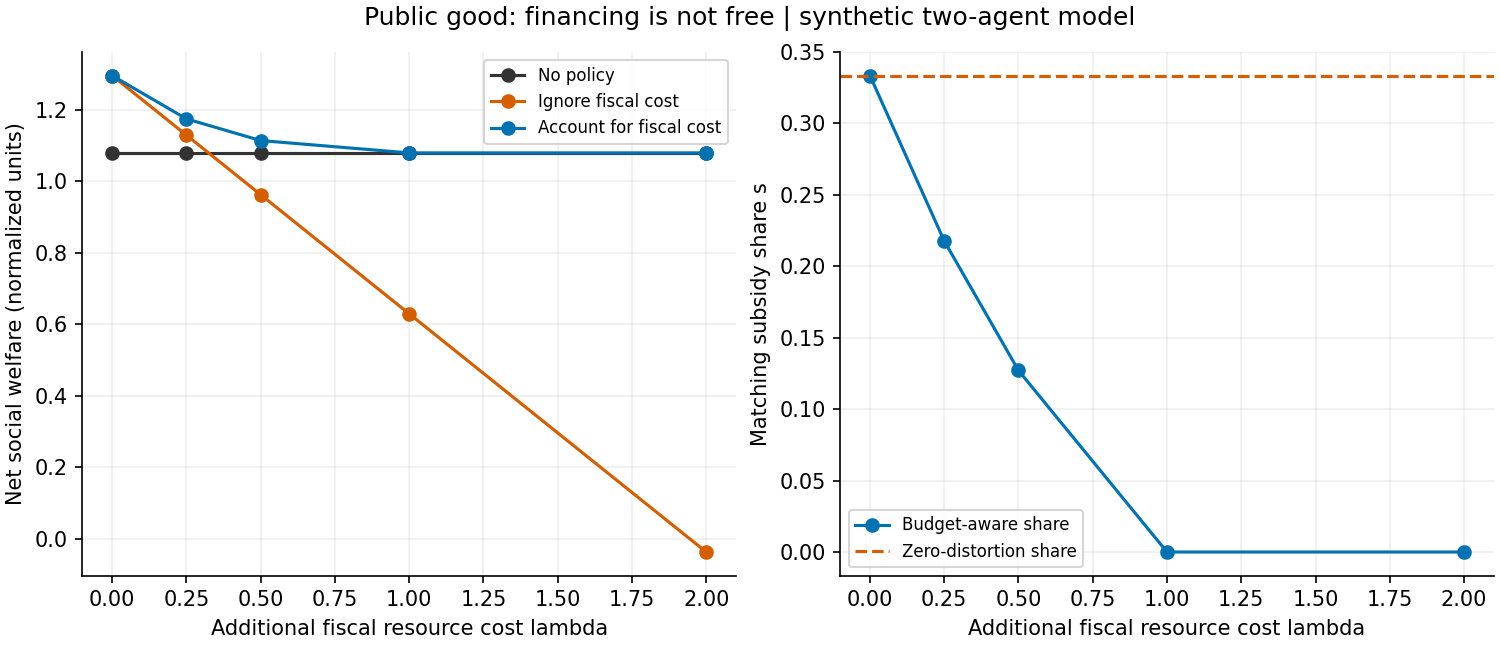

In [4]:
display(Image(filename=str(root/"results/comparison.png")))
print("Ancla",r["anchor"])

## Falsación de contabilidad
Omitir los impuestos fijos y sumar solo la utilidad antes de financiar el matching eleva artificialmente bienestar por B. La corrección no resta dos veces una transferencia: resta recursos G y la pérdida adicionalλB, según el modelo supuesto.

In [5]:
G=2
W,s,B=policy_welfare(G,1,2,0)
before_tax=3*np.log1p(G)-(1-s)*G
print("Bienestar antes de financiar",before_tax,"real",W,"diferencia",before_tax-W,"presupuesto",B)
assert abs(before_tax-W-B)<1e-12
assert optimal(1,2,0)==naive(1,2)
assert optimal(1,2,2)==no_policy(2)

Bienestar antes de financiar 1.9625035326709959 real 1.2958368660043287 diferencia 0.6666666666666672 presupuesto 0.6666666666666667


## Costes y trazabilidad
Escenario escalar fijo; costes de30casos agregados por prefijos, no benchmark de alta dimensión. Pico de asignacionesPython del experimento entero no esRSS ni memoria por brazo. Cinco referencias reales delimitan lo que no modelamos.

In [6]:
print((root/"results/costs.csv").read_text())
print("Versiones",r["versions"])
print("SHA256 datos",r["data_sha256"])
print("SHA256 núcleo",r["source_sha256"])

prefix_cases,analytic_seconds,oracle_seconds
1,3.295999999863852e-05,0.012321461999817984
10,0.00012518600078692543,0.07352715299975898
30,0.0006033890008438902,0.19170922300008897

Versiones {'python': '3.12.14', 'numpy': '2.3.5', 'scipy': '1.17.0', 'matplotlib': '3.10.8'}
SHA256 datos 100b153d063d8605ff751c2b3e9167e77596c22718d76b70e40565795b83dccd
SHA256 núcleo 6e4efb1929a6b3fef0d113356aa7794c60cf20d5baa546c20cc35d72b804b070


## Límites y siguientes pasos
El presupuesto solo equilibra en el Nash previsto. Si los impuestos dependen de desviaciones, cambian los incentivos; si hay ingreso limitado, warm glow o λ endógeno, hay otro juego. No se concluye una tasa óptima real. Siguiente: restricciones presupuestarias, financiación fuera de equilibrio y preferencias/λ identificados.

Ejecución secuencial IPython limpio en proceso sin kernel/socket; errores abortan y outputs persisten. FiguraPNG inspeccionada, sin prueba de todos los frontends.